# Cleaning dataset

Let's first load, inspect and clean the data

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)

DATA_DIR = "sample_data"  

In [2]:
## check if we got all the files, should have 2 per year - now its just one
files = sorted(glob.glob(os.path.join(DATA_DIR, "jena*.csv*")))
print(len(files), "files found:")
for f in files:
    print(" ", os.path.basename(f))

1 files found:
  jena_climate_2009_2016.csv


In [3]:
# look at one of the files to see its shape and columns
sample = pd.read_csv(files[0])
print(sample.shape)
print(sample.columns.tolist())
sample.head()

(420551, 15)
['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [4]:
# fuse the code tghter

# parse thru all the files and append - this was needed when we had 16 separate files
dfs = []
for f in files:
    part = pd.read_csv(f)
    part["source_file"] = os.path.basename(f)   # to debugging
    dfs.append(part)

# fuse all data tgether - not needed anymore
df = pd.concat(dfs, ignore_index=True)

# get date time column into datatime format. clean up errors
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S", errors="coerce")

# sort chronologically
df = df.sort_values("Date Time").reset_index(drop=True)

# Remove duplicates, can occur at start and end of file
n_before = len(df)
df = df.drop_duplicates(subset="Date Time", keep="first").reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate timestamps")

print("Shape:", df.shape)
print("Date range:", df["Date Time"].min(), "->", df["Date Time"].max())
print("Unparsed dates:", df["Date Time"].isna().sum())

Dropped 327 duplicate timestamps
Shape: (420224, 16)
Date range: 2009-01-01 00:10:00 -> 2017-01-01 00:00:00
Unparsed dates: 0


According to the TA: "To get the hourly version described in the assignment, keep every sixth row, starting from the 01:00 reading on 1 January 2009. "

In [5]:
# check if 1:00 from 1 jan 2009
print(df["Date Time"].head(7))

# get every 6th row
df = df.iloc[5::6].reset_index(drop=True)

# # round to closest min
df["Date Time"] = df["Date Time"].dt.round("min")

print("Hourly shape:", df.shape)               
print("First row:", df["Date Time"].iloc[0])   

0   2009-01-01 00:10:00
1   2009-01-01 00:20:00
2   2009-01-01 00:30:00
3   2009-01-01 00:40:00
4   2009-01-01 00:50:00
5   2009-01-01 01:00:00
6   2009-01-01 01:10:00
Name: Date Time, dtype: datetime64[ns]
Hourly shape: (70037, 16)
First row: 2009-01-01 01:00:00


ltsm requires that its data items are linear in time. That means if there are some gaps in irregular time stamps, it could cause issues. The model odesnt necessarily know that more time has passed between the two points.

One way to solve it is to interpolate a value, but the assignment removes points if there's data leakage or such things.

We can thus drop some sliding windows over these areas. Since there are not that many gaps we are not losing much traning data.

In [6]:
dt = df["Date Time"].diff().dropna()
print("Time step counts:")
print(dt.value_counts().head())

# Locate any gaps (anything other than 1 hour)
gaps = df.loc[dt[dt != pd.Timedelta(hours=1)].index, ["Date Time", "source_file"]]
gaps["gap_size"] = dt[dt != pd.Timedelta(hours=1)]
print("\nGaps found:", len(gaps))
print(gaps.head(20))

Time step counts:
Date Time
0 days 01:00:00    70031
0 days 01:10:00        2
0 days 01:20:00        1
0 days 16:50:00        1
3 days 03:10:00        1
Name: count, dtype: int64

Gaps found: 5
                Date Time                 source_file        gap_size
6729  2009-10-08 10:20:00  jena_climate_2009_2016.csv 0 days 01:20:00
38312 2013-05-16 09:30:00  jena_climate_2009_2016.csv 0 days 01:10:00
48871 2014-07-30 08:40:00  jena_climate_2009_2016.csv 0 days 01:10:00
50224 2014-09-25 09:30:00  jena_climate_2009_2016.csv 0 days 16:50:00
68490 2016-10-28 13:40:00  jena_climate_2009_2016.csv 3 days 03:10:00


for each gap that we drop, we add a segment ID (a segment consists of a bunch of non interrupted data)

In [7]:
# new segment id every time the time step isnt 1 hours
df["segment"] = (df["Date Time"].diff() != pd.Timedelta(hours=1)).cumsum()
print("Number of continuous segments:", df["segment"].nunique())
print(df.groupby("segment").size().describe())

Number of continuous segments: 6
count        6.000000
mean     11672.833333
std      11615.491008
min       1353.000000
25%       2842.500000
50%       8644.000000
75%      16339.250000
max      31583.000000
dtype: float64


In [8]:
seg_info = df.groupby("segment").agg(
    rows=("Date Time", "size"),
    start=("Date Time", "min"),
    end=("Date Time", "max"),
)
print(seg_info)
print("Total rows:", seg_info["rows"].sum())

          rows               start                 end
segment                                               
1         6729 2009-01-01 01:00:00 2009-10-08 09:00:00
2        31583 2009-10-08 10:20:00 2013-05-16 08:20:00
3        10559 2013-05-16 09:30:00 2014-07-30 07:30:00
4         1353 2014-07-30 08:40:00 2014-09-24 16:40:00
5        18266 2014-09-25 09:30:00 2016-10-25 10:30:00
6         1547 2016-10-28 13:40:00 2016-12-31 23:40:00
Total rows: 70037


In [9]:
def make_windows(data, feature_cols, target_cols, k):
    """
    data: DataFrame with a 'segment' column, sorted by time.
    Returns X of shape (N, k, n_features) and y of shape (N, n_targets).
    No window crosses a gap, because each is built inside one segment.
    """
    X_list, y_list = [], []
    for _, seg in data.groupby("segment"):
        if len(seg) <= k:          # segment too short to form even one window
            continue
        feats = seg[feature_cols].to_numpy(dtype=np.float32)
        targs = seg[target_cols].to_numpy(dtype=np.float32)
        for i in range(k, len(seg)):
            X_list.append(feats[i - k:i])   # rows t-k ... t-1
            y_list.append(targs[i])          # row t
    return np.stack(X_list), np.stack(y_list)

check missing values and any wrong data

In [10]:
print("Missing values per column:")
print(df.isna().sum())

pd.set_option("display.width", 200)
df.describe().T

Missing values per column:
Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0
source_file        0
segment            0
dtype: int64


,count,mean,min,25%,50%,75%,max,std
Date Time,70037,2012-12-30 09:32:40.320973312,2009-01-01 01:00:00,2010-12-31 14:20:00,2012-12-30 03:20:00,2014-12-30 08:30:00,2016-12-31 23:40:00,NaN
p (mbar),70037.0,989.213986,913.6,984.21,989.58,994.72,1015.35,8.361265
T (degC),70037.0,9.443924,-22.76,3.35,9.4,15.47,37.1,8.422167
Tpot (K),70037.0,283.486415,250.85,277.43,283.45,289.52,311.04,8.503137
Tdew (degC),70037.0,4.95448,-24.8,0.23,5.21,10.08,23.06,6.73049
rh (%),70037.0,76.02761,13.88,65.23,79.3,89.4,100.0,16.461357
VPmax (mbar),70037.0,13.570414,0.97,7.77,11.81,17.6,63.15,7.736667
VPact (mbar),70037.0,9.532792,0.81,6.21,8.86,12.36,28.25,4.183617
VPdef (mbar),70037.0,4.037556,0.0,0.87,2.19,5.29,45.41,4.893291
sh (g/kg),70037.0,6.021796,0.51,3.92,5.59,7.8,18.07,2.655797


In [11]:
# Known issue in this dataset: wind velocity columns contain -9999 placeholders
wind_cols = [c for c in df.columns if "wv" in c.lower()]
for c in wind_cols:
    print(f"{c}: min={df[c].min():.2f}, count(<0)={(df[c] < 0).sum()}")

# Check the 4 required columns for physically implausible values
target_cols = ["p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]
for c in target_cols:
    print(f"{c}: min={df[c].min():.2f}, max={df[c].max():.2f}")

wv (m/s): min=-9999.00, count(<0)=3
max. wv (m/s): min=-9999.00, count(<0)=3
p (mbar): min=913.60, max=1015.35
T (degC): min=-22.76, max=37.10
rh (%): min=13.88, max=100.00
wv (m/s): min=-9999.00, max=14.01


In [12]:

# replace anything that's -9999 with Nan
for c in target_cols:
    if c == "rh (%)":
        df.loc[df[c] <= 0, c] = np.nan # we cant have humuditiy of 0 or less
    else:
        df.loc[df[c] < -9000, c] = np.nan
# fill using past value. we are not interpolating
df[target_cols] = df[target_cols].ffill()
#print out the max and min of each feature
print(df[target_cols].describe().T[["min", "max"]])



             min      max
p (mbar)  913.60  1015.35
T (degC)  -22.76    37.10
rh (%)     13.88   100.00
wv (m/s)    0.00    14.01


min max values look normal!
lets now plot it out to double check

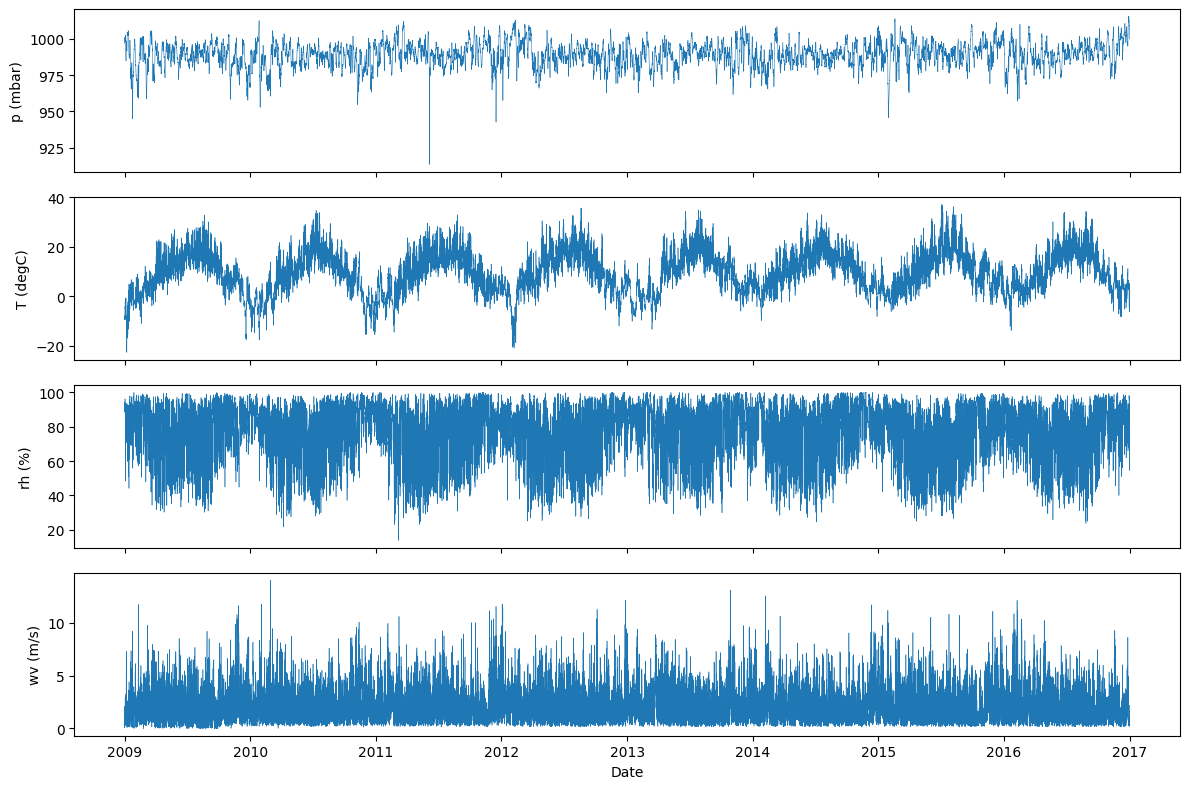

In [13]:
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(df["Date Time"], df[c], linewidth=0.4)
    ax.set_ylabel(c)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

the plots look like there are sitll some extremeties. Look at the atmospheric pressure, it has a shap spike to a low pressure. We can then plot in a closer look up to see if it was a sensor glitch or the data is legit. Also the other data seem to within good ranges, so no need to investigate.

In [14]:
checks = {
    "T (degC)": df["T (degC)"] < -30, #values found online/common sense indicating lowest mean temperature for that region in germany
    "p (mbar)": df["p (mbar)"] < 950,
    "rh (%)":   df["rh (%)"] < 5,
    "wv (m/s)": df["wv (m/s)"] > 20,
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()} rows flagged")
    print(df.loc[mask, ["Date Time", "p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]].head(20))
    print()

T (degC): 0 rows flagged
Empty DataFrame
Columns: [Date Time, p (mbar), T (degC), rh (%), wv (m/s)]
Index: []

p (mbar): 31 rows flagged
                Date Time  p (mbar)  T (degC)  rh (%)  wv (m/s)
541   2009-01-23 14:00:00    947.77      0.52    90.3      8.90
542   2009-01-23 15:00:00    946.05      1.55    86.2      9.19
543   2009-01-23 16:00:00    945.13      2.00    86.5      7.77
544   2009-01-23 17:00:00    944.88      3.64    84.8      6.22
545   2009-01-23 18:00:00    944.99      4.79    81.2      6.46
546   2009-01-23 19:00:00    945.96      5.40    78.4      5.58
547   2009-01-23 20:00:00    946.90      5.10    80.3      4.47
548   2009-01-23 21:00:00    948.43      5.68    78.9      3.74
549   2009-01-23 22:00:00    949.80      5.34    77.7      4.33
21276 2011-06-06 13:20:00    913.60     25.11    53.7      3.59
25906 2011-12-16 11:20:00    949.88      3.24    85.1      8.78
25907 2011-12-16 12:20:00    947.13      3.64    83.9      5.67
25908 2011-12-16 13:20:00    94

lets observe closer to there timestamps

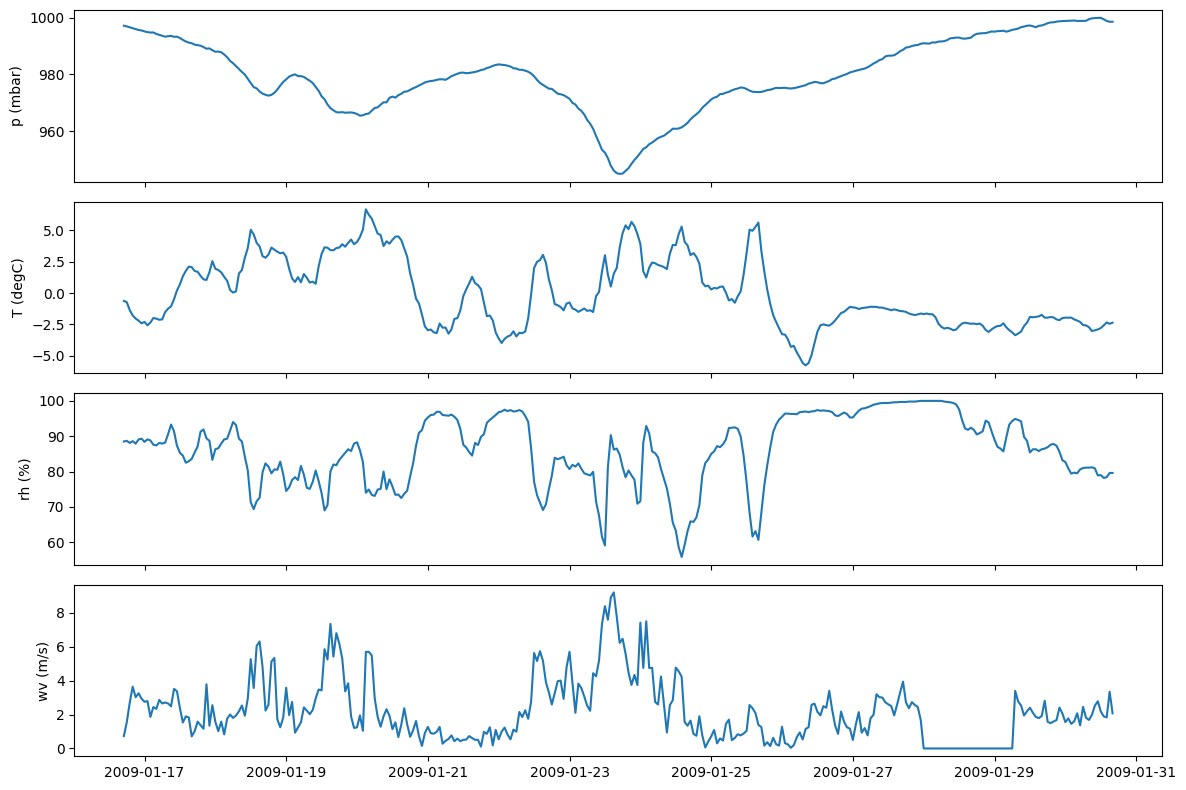

In [15]:
# zoom into to see if temperature was wrong to see the weekly pattern
week = df.iloc[544-24*7:544+24 * 7] # across two weeks
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Smooth data, looks good

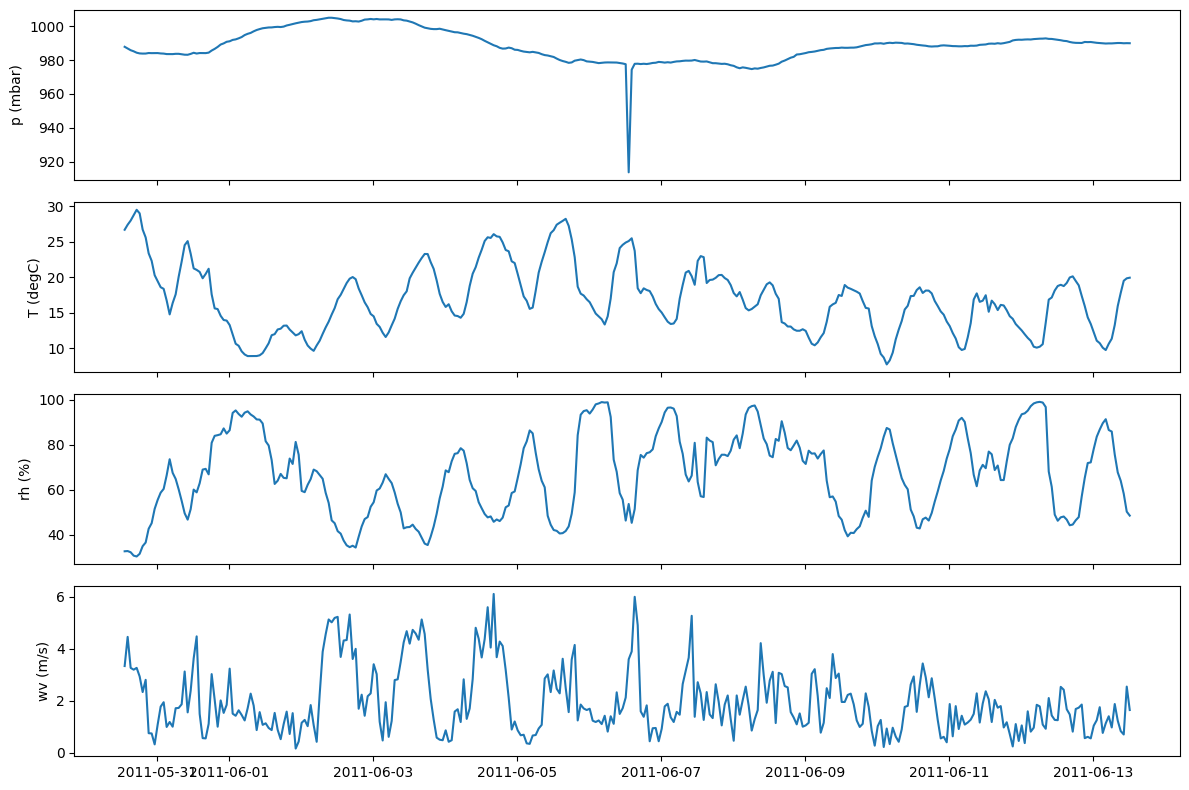

In [16]:
week = df.iloc[21276 -24*7:21276 +24 * 7] # before and after a week
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Seems like a sensor error, lets reject this point

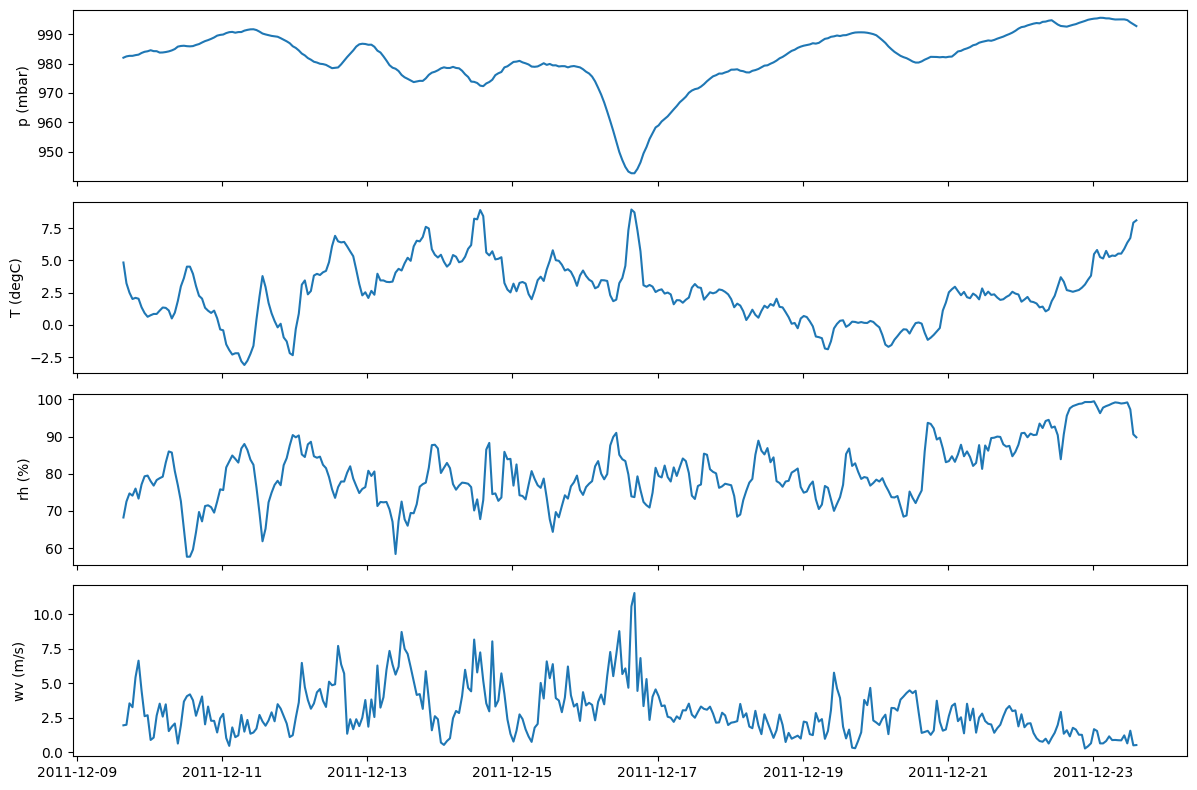

In [17]:
week = df.iloc[25910 - 24*7:25910 +24 * 7]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

looks smooth enough. we keep this data

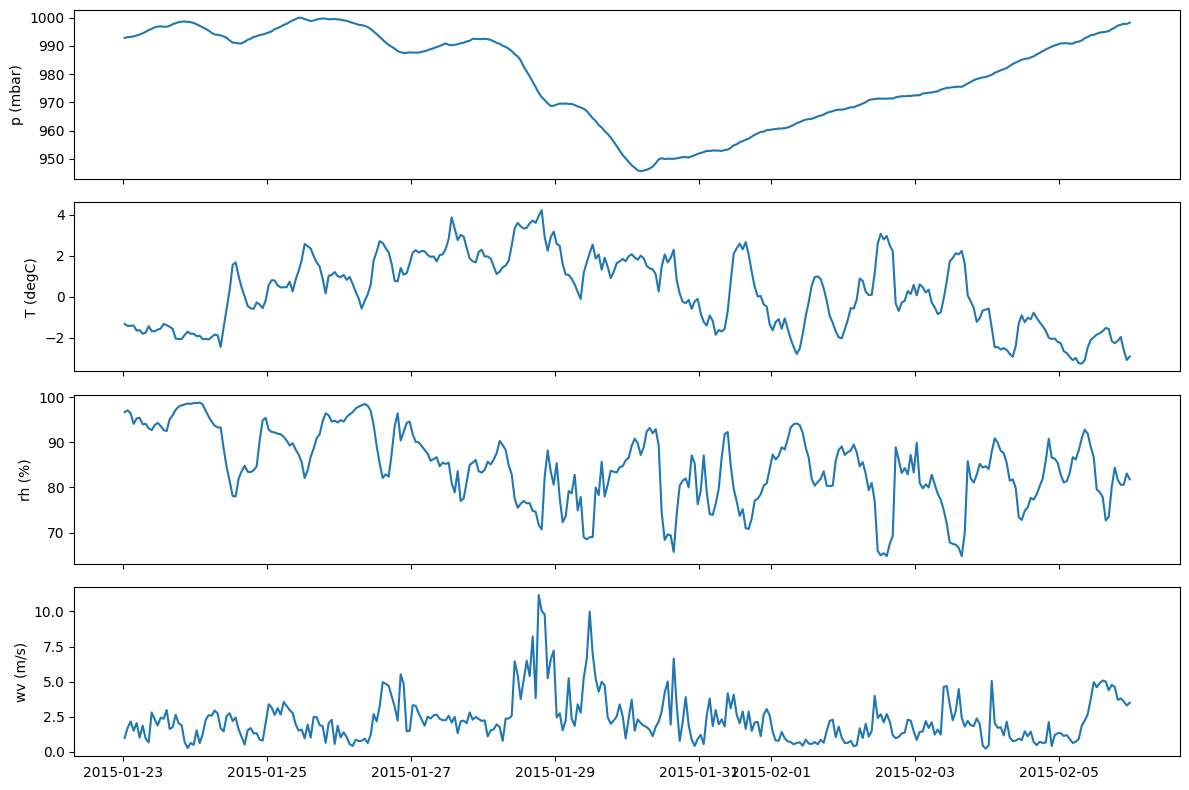

In [18]:
week = df.iloc[53263 - 7*24:53263 +7*24]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Smooth change. That is normal.

In the end we only discard one sensor data error at timestamp 21276

In [19]:
print(df.loc[21276, target_cols]) # making sure we have the right timestamp to remove

p (mbar)    913.6
T (degC)    25.11
rh (%)       53.7
wv (m/s)     3.59
Name: 21276, dtype: object


In [20]:
df.loc[21276, target_cols] = np.nan 
# fill using past value. we are not interpolating
df[target_cols] = df[target_cols].ffill()
#print out the max and min of each feature
print(df[target_cols].describe().T[["min", "max"]])

             min      max
p (mbar)  942.65  1015.35
T (degC)  -22.76    37.10
rh (%)     13.88   100.00
wv (m/s)    0.00    14.01


MIn/Max values look normal! Let's now plot it out

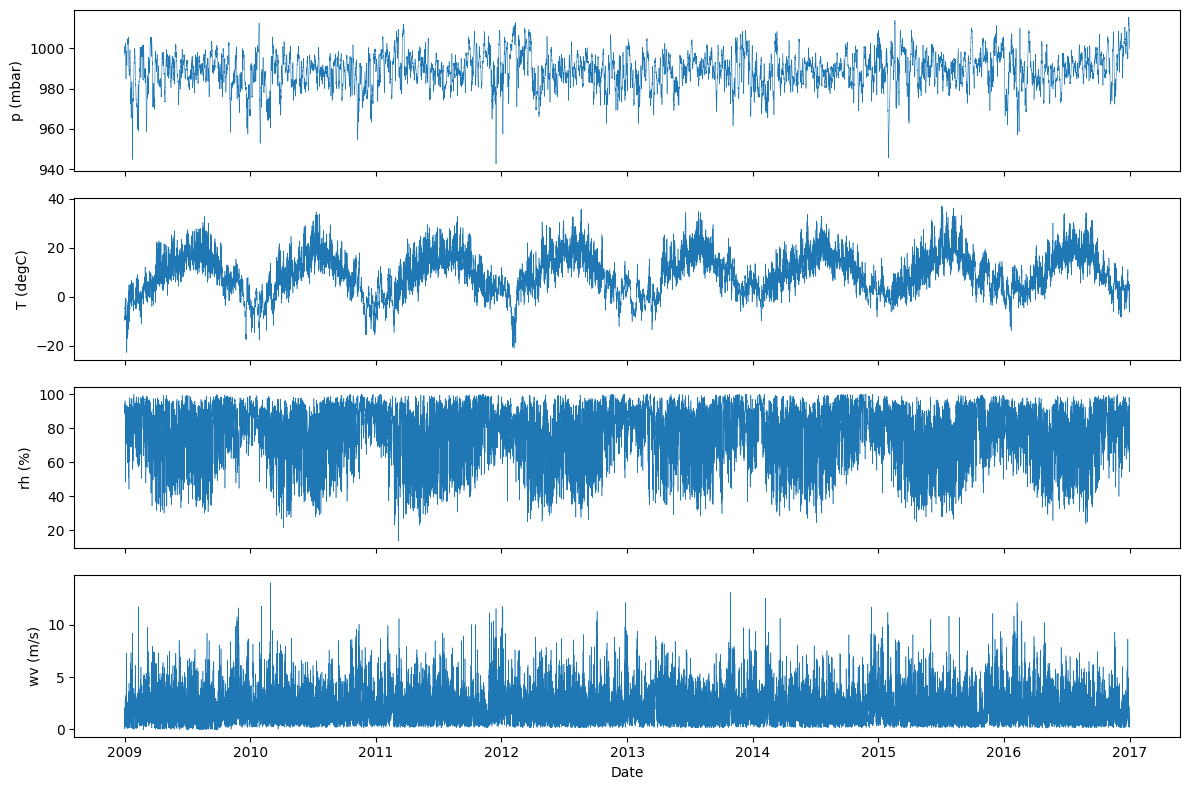

In [21]:
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(df["Date Time"], df[c], linewidth=0.4)
    ax.set_ylabel(c)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

It looks good! There is no obvious spike or erronous data.

# Splitting the dataset


Let's now split the dataset into the training, validation and test set. Note that with LTSM models, we need to keep them in chronological order.

In [22]:
df["year"] = df["Date Time"].dt.year

train_df = df[df["year"] <= 2014].copy()
val_df   = df[df["year"] == 2015].copy()
test_df  = df[df["year"] == 2016].copy()

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name}: {len(part):6d} rows")

train:  52567 rows
val:   8760 rows
test:   8710 rows


This is roughly 75.06%, 12.51%, 12.44% split. We can average it to 75, 12.5, 12.5 split. Note: the gap of 50 less rows in test is normal, since in 2016, there was a huge gap of around 2-3 days where no data was collected.

In [23]:
MAX_K = 8  # longest history used in the k study
k = 4
batch_size = 64

# For now, four input features are also our four targets
feature_cols = target_cols.copy()

# fit scaler only on training data to avoid data leakage
scaler = StandardScaler()
scaler.fit(train_df[feature_cols])

def normalize_df(data):
    normalized = data.copy()
    normalized[feature_cols] = scaler.transform(data[feature_cols])
    return normalized

# identical normalization to all splits
train_norm = normalize_df(train_df)
val_norm = normalize_df(val_df)
test_norm = normalize_df(test_df)

X_train, y_train = make_windows(train_norm, feature_cols, target_cols, k)
X_val, y_val = make_windows(val_norm, feature_cols, target_cols, k)
X_test, y_test = make_windows(test_norm, feature_cols, target_cols, k)

# create dataloaders
def create_loader(X, y, shuffle=False, batch_size_override=None, seed=None):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )
    generator = torch.Generator().manual_seed(int(seed)) if seed is not None else None
    return DataLoader(dataset, batch_size=batch_size_override or batch_size,
                      shuffle=shuffle, generator=generator)

train_loader = create_loader(X_train, y_train, shuffle=True)
val_loader = create_loader(X_val, y_val)
test_loader = create_loader(X_test, y_test)

# train + val combined, for the final training after early stopping
X_trainval = np.concatenate([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])
trainval_loader = create_loader(X_trainval, y_trainval, shuffle=True)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Train+Validation:", X_trainval.shape, y_trainval.shape)
print("Test:", X_test.shape, y_test.shape)
print("Train means:", train_norm[feature_cols].mean().round(4).to_dict())

# ----------- setup up k for hyperparameters tuning ------------
# New: make k=4,...,8 comparable on IDENTICAL target timestamps.
# Each split creates segment-safe k=8 windows once; shorter k takes a suffix.
aligned_windows = {
    "train": make_windows(train_norm, feature_cols, target_cols, MAX_K),
    "val": make_windows(val_norm, feature_cols, target_cols, MAX_K),
    "test": make_windows(test_norm, feature_cols, target_cols, MAX_K),
}

def get_k_data(k_value, batch_size_override=None, seed=SEED):
    """Return loaders for k=4..8 using the same prediction targets for every k."""
    if not (4 <= k_value <= MAX_K):
        raise ValueError(f"k must be between 4 and {MAX_K}")

    # prepare sequence of k length
    prepared = {
        name: (windows[:, -k_value:, :], targets)
        for name, (windows, targets) in aligned_windows.items()
    }
    xtr, ytr = prepared["train"]
    xva, yva = prepared["val"]
    xte, yte = prepared["test"]
    return {
        "train_loader": create_loader(xtr, ytr, True, batch_size_override, seed),
        "val_loader": create_loader(xva, yva, False, batch_size_override),
        "test_loader": create_loader(xte, yte, False, batch_size_override),
        "trainval_loader": create_loader(np.concatenate([xtr, xva]), np.concatenate([ytr, yva]), True, batch_size_override, seed),
        "X_test": xte,
        "y_test": yte,
    }

print("Original k=4 train/val/test:", X_train.shape, X_val.shape, X_test.shape)
print("Aligned k=8 train/val/test:", *(aligned_windows[s][0].shape for s in ["train", "val", "test"]))
print("Train means:", train_norm[feature_cols].mean().round(4).to_dict())

Train: (52547, 4, 4) (52547, 4)
Validation: (8756, 4, 4) (8756, 4)
Train+Validation: (61303, 4, 4) (61303, 4)
Test: (8702, 4, 4) (8702, 4)
Train means: {'p (mbar)': -0.0, 'T (degC)': -0.0, 'rh (%)': 0.0, 'wv (m/s)': -0.0}
Original k=4 train/val/test: (52547, 4, 4) (8756, 4, 4) (8702, 4, 4)
Aligned k=8 train/val/test: (52527, 8, 4) (8752, 8, 4) (8694, 8, 4)
Train means: {'p (mbar)': -0.0, 'T (degC)': -0.0, 'rh (%)': 0.0, 'wv (m/s)': -0.0}


In [24]:
# Check that every segment contains consecutive hourly observations
for split_name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    for segment_id, seg in split.groupby("segment"):
        time_diff = seg["Date Time"].diff().dropna()

        assert (time_diff == pd.Timedelta(hours=1)).all(), (
            f"{split_name}: irregular timestamps in segment {segment_id}"
        )

    expected_windows = sum(
        max(0, len(seg) - k)
        for _, seg in split.groupby("segment")
    )

    actual_windows = len(
        make_windows(split, feature_cols, target_cols, k)[0]
    )

    assert actual_windows == expected_windows
    print(f"{split_name}: {actual_windows} valid windows")

# Verify normalized data is finite
for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    assert np.isfinite(X).all(), f"{name}: invalid inputs"
    assert np.isfinite(y).all(), f"{name}: invalid targets"

print("All preprocessing tests passed.")


Train: 52547 valid windows
Validation: 8756 valid windows
Test: 8702 valid windows
All preprocessing tests passed.


# Model Classes

In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F

The following is the basis for a fully connected neural network, using ReLu as its activation function (since this is the typical default and we have no reason to believe we need something else). It is based on the code shown in tutorial 2, with expansion to allow for multiple hidden layers.

In [26]:
class FullyConnectedNN(nn.Module):
    def __init__(self, k=4, in_attrs=4, out=4, layers=2, hidden_size=8):
        """
        params:
            k: number of timesteps leading up to time t 
            in_attrs: number of attributes to be considered for each proceeding timestep
            out: number of predicted attributes
            layers: number layers, excluding output
            hidden_size: size of hidden layers
        """
        super(FullyConnectedNN, self).__init__()
        self.input_layer = nn.Linear(k * in_attrs, hidden_size)
        if layers > 1:
            # extra hidden layers (ModuleList so PyTorch trains their weights)
            self.hidden_layers = nn.ModuleList(
                [nn.Linear(hidden_size, hidden_size) for _ in range(layers - 1)]
            )
        else:
            self.hidden_layers = None
        self.output_layer = nn.Linear(hidden_size, out)

    def forward(self, x):
        x = x.flatten(1) # need to transform input dimension (batch, k, 4) -> (batch, k*4)
        hidden_result = torch.relu(self.input_layer(x))
        if self.hidden_layers is not None:
            for layer in self.hidden_layers:
                hidden_result = torch.relu(layer(hidden_result))
        return self.output_layer(hidden_result)

In [27]:
# test for FCNN
m = FullyConnectedNN()
print(m(torch.randn(2, 4, 4)).shape)              # torch.Size([2, 4])
print(FullyConnectedNN(layers=1)(torch.randn(2, 4, 4)).shape)   # also torch.Size([2, 4])

torch.Size([2, 4])
torch.Size([2, 4])


The following is a very simple LSTM, based on tutorial 9.

In [28]:
class LSTM(nn.Module):
    def __init__(self, in_attrs=4, out=4, hidden_size=8, layers=2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=in_attrs,
            hidden_size=hidden_size,
            num_layers=layers,
            batch_first=True        # batch_first=True tells LSTM that first dimension is batch size and 2nd dim is time
        )

        self.output = nn.Linear(hidden_size, out)

    def forward(self, x):
        # x: (batch_size, k, in_attrs)
        sequence_output, (h_n, c_n) = self.lstm(x)

        # Last hidden state from final LSTM layer
        last_hidden = h_n[-1]

        # predict 4 weather attributes
        return self.output(last_hidden)

**LSTM**

`batch_first=True` tells PyTorch that the first dimension is the batch size and the second dimension is time. Without it, the LSTM would interpret the dimensions incorrectly.

The LSTM receives input shaped `(batch_size, k, 4)`. Here k is selected from 4 through 8; the recurrent input size remains four for all k.

For each observation, it updates its hidden state and cell state. After processing all four historical timesteps, it produces a representation containing information about the sequence. The last hidden state has shape `(batch_size, 8)`, and a linear layer maps the eight hidden features to the four weather predictions.

The final output shape is `(batch_size, 4)`.

In [29]:
# test LSTM
m = LSTM()
print(m(torch.randn(2, 4, 4)).shape)                 # torch.Size([2, 4])
print(LSTM(layers=1)(torch.randn(2, 4, 4)).shape)    # torch.Size([2, 4])

torch.Size([2, 4])
torch.Size([2, 4])


**RNN**

For the model of our choice, we decided to make a basic RNN to act as the middleman of complexity between a simple feedforward network and an LSTM. It uses tanh activation, the default for Pytorch's RNNs. We think it could still be effective since we have a relatively small input (with only 4-8 timesteps considered) and thus may be able to avoid vanishing gradients. 

In [30]:
class RNN(nn.Module):
    def __init__(self, in_attrs=4, out=4, hidden_size=8, layers=2):
        """
        params:
            in_attrs: number of attributes to be considered for each proceeding timestep
            out: number of predicted attributes
            hidden_size: size of hidden representations
            layers: number layers, excluding output
        """
        super().__init__()
        # need to set batch_first = True for RNN to match data shape
        self.rnn = nn.RNN(input_size=in_attrs, hidden_size=hidden_size, num_layers=layers, nonlinearity='tanh', batch_first=True)
        self.output = nn.Linear(hidden_size, out)

    def forward(self, x):
        # unpack tuple 
        sequence,_ = self.rnn(x)

        # take output at the last time step (t−1) to predict t
        return self.output(sequence[:, -1, :])

In [31]:
# quick test for RNN model
m = RNN()
print(m(torch.randn(2, 4, 4)).shape)    # torch.Size([2, 4])
print(RNN(layers=1)(torch.randn(2, 4, 4)).shape)   # also torch.Size([2, 4])
print(m(torch.randn(2, 8, 4)).shape)    # k=8 also works: torch.Size([2, 4])

torch.Size([2, 4])
torch.Size([2, 4])
torch.Size([2, 4])


# Training, k study, and model selection

All three architectures have two hidden/recurrent layers, use MSE on standardized weather attributes, and are trained with Adam using mini-batches. We will also be using Early Stopping to preserve computational resources and find an optimal number of epochs to train for. We first compare `k` from 4 to 8 on identical validation target timestamps, then tune hidden size, learning rate, and weight decay for each model. The selected configurations are confirmed using seed 42. We do **not** use 2016 test results for tuning. Best epochs are determined using validation data; final models are initialized from scratch and trained on combined 2009-2015 data for the selected epoch count.

Note: k had very little effect (all differences under 0.001 val MSE), so we fixed a common k = 7 for a fair comparison.

In [32]:
import copy
import random
from pathlib import Path

max_epochs = 50
patience = 5
LAYERS = 2  # keep identical depth for all three models
K_VALUES = [4, 5, 6, 7, 8]
SEEDS = [42]

# set of hyperparameters tunning : (hidden_size, learning rate, weight decay for Adam optimizer)
TUNING_OPTIONS = (
    [
        (8, 1e-3, 0.0),
        (16, 1e-3, 0.0),
        (32, 1e-3, 0.0),
        (16, 3e-4, 0.0),
        (32, 3e-4, 0.0),
        (16, 1e-3, 1e-4),
    ]
)

# Setup output folder to save results
RESULT_DIR = Path('results_part3_inplace') / ('full')
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Setup device
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")     # NVIDIA GPU
# elif torch.backends.mps.is_available():
#     DEVICE = torch.device("mps")      # Apple Silicon GPU (Mac)
else:
    DEVICE = torch.device("cpu")      # CPU fallback

print('Mode:','FULL STUDY', '| device:', DEVICE)

Mode: FULL STUDY | device: cpu


In [ ]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def early_stopping_train(model, optimizer, train_loader, val_loader):
    model.to(DEVICE)
    no_improvement_count = 0
    best_epoch = 0
    best_loss = float("inf")
    train_losses = []  # array to save train loss for each epoch
    val_losses = []  # array to val loss for each epoch

    for epoch in range(max_epochs):
        model.train()
        train_running_loss = 0 
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            y_hat = model(x)
            loss = F.mse_loss(y_hat, y)
            loss.backward()
            optimizer.step()
            train_running_loss += loss.item() * x.size(0)  # add up batch losses
        train_running_loss /= len(train_loader.dataset)  # compute average loss per epoch for plotting

        model.eval()
        with torch.no_grad():
            running_loss = 0
            for x, y in val_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                y_hat = model(x)
                running_loss += F.mse_loss(y_hat, y).item() * x.size(0)  # .item() gives a plain number and scale back as MSE is average
            running_loss /= len(val_loader.dataset)  # number of batches -> average loss per batch

        # save for plotting
        train_losses.append(train_running_loss) 
        val_losses.append(running_loss)
        # print(f"Epoch {epoch + 1}: train loss {train_running_loss:.4f}, val loss {running_loss:.4f}")

        if running_loss < best_loss:
            best_loss = running_loss
            best_epoch = epoch
            no_improvement_count = 0 # reset counter when loss improves
        else:
            no_improvement_count += 1
            if no_improvement_count > patience:
                print(f"Stopped early. Best epoch {best_epoch + 1}, with validation loss {best_loss:.4f}")
                return best_epoch + 1, train_losses, val_losses
            
    print(f"Continued to maximum epoch {max_epochs} with best validation loss {best_loss:.4f}")
    return best_epoch + 1, train_losses, val_losses 


# plotting function
def plot_losses(train_losses, val_losses, title):
    epochs_range = range(1, len(train_losses) + 1)
    plt.plot(epochs_range, train_losses, label="train")
    plt.plot(epochs_range, val_losses, label="validation")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss (normalized)")
    plt.title(title)
    plt.legend()
    plt.show()

def make_model(model_name, window_k, hidden_size=8, layers=LAYERS):
    """Creates existing model classes; the FCNN needs its input k explicitly."""
    if model_name == 'FCNN':
        return FullyConnectedNN(k=window_k, hidden_size=hidden_size, layers=layers)
    if model_name == 'LSTM':
        return LSTM(hidden_size=hidden_size, layers=layers)
    if model_name == 'RNN':
        return RNN(hidden_size=hidden_size, layers=layers)
    raise ValueError(f'Unknown model: {model_name}')

def run_experiment(model_name, window_k, hidden_size=8, lr=1e-3, weight_decay=0.0, seed=SEED):
    """Fit on train, select best epoch on validation"""
    seed_everything(seed)
    loaders = get_k_data(window_k, seed=seed)
    model = make_model(model_name, window_k, hidden_size)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_epoch, train_losses, val_losses = early_stopping_train(
        model, optimizer, loaders['train_loader'], loaders['val_loader']
    )
    row = {
        'model': model_name, 'k': int(window_k), 'hidden_size': int(hidden_size),
        'layers': LAYERS, 'lr': float(lr), 'weight_decay': float(weight_decay),
        'seed': int(seed), 'best_epoch': int(best_epoch),
        'val_mse': float(min(val_losses)),
        'parameters': sum(p.numel() for p in model.parameters() if p.requires_grad),
    }
    print(f"{model_name}: k={window_k}, hidden={hidden_size}, lr={lr:g}, "f"wd={weight_decay:g}, seed={seed}: val MSE={row['val_mse']:.5f}")
    return row, (train_losses, val_losses)


def run_model_study(model_name):
    """Run k study, hyperparameter tuning, and seed confirmation."""

    # Step 1: k study with fixed hyperparameters
    k_trials = [
        (candidate_k, *run_experiment(model_name, candidate_k))
        for candidate_k in K_VALUES
    ]

    k_rows = [row for _, row, _ in k_trials]
    k_histories = {
        candidate_k: history
        for candidate_k, _, history in k_trials
    }
    k_df = pd.DataFrame(k_rows).sort_values("k")

    # Use common k=7 for final comparison
    best_k = 7 if 7 in K_VALUES else K_VALUES[0]
    print(f"Using common k={best_k} for {model_name}")

    # Step 2: Model-specific hyperparameter tuning
    tune_rows = []
    history_by_key = {}

    for hidden_size, lr, wd in TUNING_OPTIONS:

        # Reuse the baseline from the k study
        if (hidden_size, lr, wd) == (8, 1e-3, 0.0):
            row = k_df.loc[k_df["k"] == best_k].iloc[0].to_dict()
            history = k_histories[best_k]
        else:
            row, history = run_experiment(
                model_name, best_k, hidden_size, lr, wd
            )

        tune_rows.append(row)
        history_by_key[(int(hidden_size), float(lr), float(wd))] = history

    tune_df = pd.DataFrame(tune_rows).sort_values("val_mse")

    # Step 3: Confirm top 2 configurations with multiple seeds
    finalists = tune_df.head(2)
    confirmations = []

    for _, cfg in finalists.iterrows():
        for seed in SEEDS:
            if seed == SEED:
                row = cfg.to_dict()
            else:
                row, _ = run_experiment(
                    model_name,
                    best_k,
                    int(cfg["hidden_size"]),
                    float(cfg["lr"]),
                    float(cfg["weight_decay"]),
                    seed
                )

            confirmations.append(row)

    confirm_df = pd.DataFrame(confirmations)

    group_cols = ["k", "hidden_size", "lr", "weight_decay"]

    summary = (
        confirm_df.groupby(group_cols, as_index=False)
        .agg(
            mean_val_mse=("val_mse", "mean"),
            std_val_mse=("val_mse", "std"),
            chosen_epochs=("best_epoch", "median")
        )
        .sort_values("mean_val_mse")
    )

    # Select hyperparameters using mean validation MSE
    selected = summary.iloc[0]

    best_config = {
        "model": model_name,
        "k": int(selected["k"]),
        "hidden_size": int(selected["hidden_size"]),
        "layers": LAYERS,
        "lr": float(selected["lr"]),
        "weight_decay": float(selected["weight_decay"]),
        "epochs": max(1, int(round(selected["chosen_epochs"]))),
        "mean_val_mse": float(selected["mean_val_mse"])
    }

    # Plot the selected configuration's validation run
    chosen_key = (
        best_config["hidden_size"],
        best_config["lr"],
        best_config["weight_decay"]
    )

    if chosen_key in history_by_key:
        plot_losses(
            *history_by_key[chosen_key],
            title=f"{model_name} selected validation run"
        )

    print(f"Selected {model_name} configuration: {best_config}")

    return best_config, k_df, tune_df, confirm_df

# def train_for_epochs(model, optimizer, train_loader, epochs):
#     for epoch in range(epochs):
#         model.train()
#         for x, y in train_loader:
#             optimizer.zero_grad()
#             y_hat = model(x)
#             loss = F.mse_loss(y_hat, y)
#             loss.backward()
#             optimizer.step()
#     print(f"Final training loss (last batch): {loss.item():.4f}")
#     return model


def train_for_epochs(model, optimizer, train_loader, epochs):
    model.to(DEVICE)

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            optimizer.zero_grad()
            y_hat = model(x)
            loss = F.mse_loss(y_hat, y)
            loss.backward()
            optimizer.step()

            # Accumulate loss weighted by batch size
            total_loss += loss.item() * x.size(0)

        avg_loss = total_loss / len(train_loader.dataset)

    print(f"Final training average MSE: {avg_loss:.5f}")

    return model


def run_full_training(best_config):
    """Train a fresh model on combined training and validation data."""

    seed_everything(SEED)

    # Get selected hyperparameters
    model_name = best_config["model"]
    k = best_config["k"]
    hidden_size = best_config["hidden_size"]
    lr = best_config["lr"]
    wd = best_config["weight_decay"]
    epochs = best_config["epochs"]

    # Combine training and validation data
    loaders = get_k_data(k, seed=SEED)

    # Initialize a fresh model
    model = make_model(model_name, k, hidden_size, layers=best_config["layers"])

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    # Train for the selected number of epochs
    model = train_for_epochs(model, optimizer, loaders["trainval_loader"], epochs)

    print(f"Finished training {model_name} for {epochs} epochs")

    return model

Stopped early. Best epoch 29, with validation loss 0.1082
FCNN: k=4, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10817
Stopped early. Best epoch 36, with validation loss 0.1078
FCNN: k=5, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10777
Stopped early. Best epoch 19, with validation loss 0.1088
FCNN: k=6, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10878
Stopped early. Best epoch 36, with validation loss 0.1086
FCNN: k=7, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10858
Stopped early. Best epoch 36, with validation loss 0.1083
FCNN: k=8, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10832
Using common k=7 for FCNN
Stopped early. Best epoch 29, with validation loss 0.1071
FCNN: k=7, hidden=16, lr=0.001, wd=0, seed=42: val MSE=0.10711
Stopped early. Best epoch 19, with validation loss 0.1072
FCNN: k=7, hidden=32, lr=0.001, wd=0, seed=42: val MSE=0.10723
Continued to maximum epoch 50 with best validation loss 0.1075
FCNN: k=7, hidden=16, lr=0.0003, wd=0, seed=42: val MSE=0.10752
Stopp

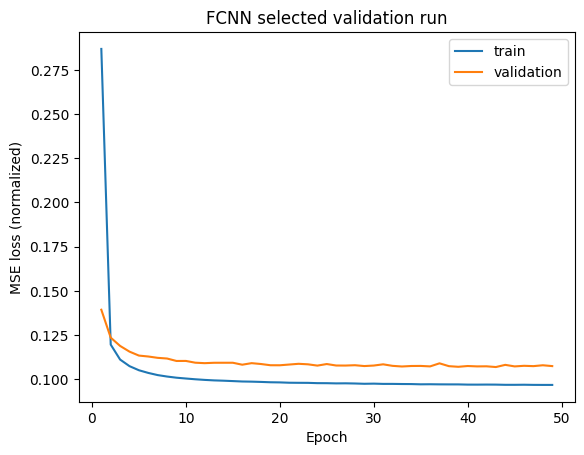

Selected FCNN configuration: {'model': 'FCNN', 'k': 7, 'hidden_size': 32, 'layers': 2, 'lr': 0.0003, 'weight_decay': 0.0, 'epochs': 43, 'mean_val_mse': 0.10686831508628629}
FCNN tuning results:


,model,k,hidden_size,layers,lr,weight_decay,seed,best_epoch,val_mse,parameters
4,FCNN,7,32,2,0.0003,0.0000,42,43,0.106868,2116
1,FCNN,7,16,2,0.0010,0.0000,42,29,0.107106,804
5,FCNN,7,16,2,0.0010,0.0001,42,29,0.107195,804
2,FCNN,7,32,2,0.0010,0.0000,42,19,0.107234,2116
3,FCNN,7,16,2,0.0003,0.0000,42,50,0.107515,804
0,FCNN,7,8,2,0.0010,0.0000,42,36,0.108583,340


... Final training on combined 2009-2015 data
Final training average MSE (last epoch): 0.09807
Finished training FCNN for 43 epochs


In [35]:
# FCNN model study
fc_config, fc_k_results, fc_tuning_results, fc_confirmation = run_model_study("FCNN")

print("FCNN tuning results:")
display(fc_tuning_results)

# Final training on combined 2009-2015 data
print("... Final training on combined 2009-2015 data")
fc_model = run_full_training(fc_config)

Stopped early. Best epoch 21, with validation loss 0.1078
LSTM: k=4, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10781
Stopped early. Best epoch 21, with validation loss 0.1077
LSTM: k=5, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10773
Stopped early. Best epoch 19, with validation loss 0.1077
LSTM: k=6, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10769
Stopped early. Best epoch 19, with validation loss 0.1075
LSTM: k=7, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10751
Stopped early. Best epoch 21, with validation loss 0.1073
LSTM: k=8, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10726
Using common k=7 for LSTM
Stopped early. Best epoch 19, with validation loss 0.1072
LSTM: k=7, hidden=16, lr=0.001, wd=0, seed=42: val MSE=0.10715
Stopped early. Best epoch 16, with validation loss 0.1064
LSTM: k=7, hidden=32, lr=0.001, wd=0, seed=42: val MSE=0.10643
Stopped early. Best epoch 33, with validation loss 0.1068
LSTM: k=7, hidden=16, lr=0.0003, wd=0, seed=42: val MSE=0.10685
Stopped ea

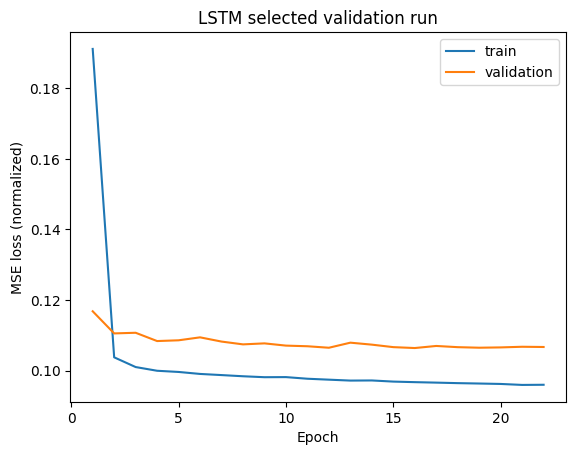

Selected LSTM configuration: {'model': 'LSTM', 'k': 7, 'hidden_size': 32, 'layers': 2, 'lr': 0.001, 'weight_decay': 0.0, 'epochs': 16, 'mean_val_mse': 0.10643441642769076}
LSTM tuning results:


,model,k,hidden_size,layers,lr,weight_decay,seed,best_epoch,val_mse,parameters
2,LSTM,7,32,2,0.0010,0.0000,42,16,0.106434,13444
4,LSTM,7,32,2,0.0003,0.0000,42,19,0.106507,13444
3,LSTM,7,16,2,0.0003,0.0000,42,33,0.106849,3652
1,LSTM,7,16,2,0.0010,0.0000,42,19,0.107151,3652
5,LSTM,7,16,2,0.0010,0.0001,42,19,0.107476,3652
0,LSTM,7,8,2,0.0010,0.0000,42,19,0.107509,1060


... Final training on combined 2009-2015 data
Final training average MSE (last epoch): 0.09796
Finished training LSTM for 16 epochs


In [36]:
# LSTM model study
lstm_config, lstm_k_results, lstm_tuning_results, lstm_confirmation = run_model_study("LSTM")

print("LSTM tuning results:")
display(lstm_tuning_results)

# Final training on combined 2009-2015 data
print("... Final training on combined 2009-2015 data")
lstm_model = run_full_training(lstm_config)

Stopped early. Best epoch 19, with validation loss 0.1091
RNN: k=4, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10905
Stopped early. Best epoch 19, with validation loss 0.1096
RNN: k=5, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10958
Stopped early. Best epoch 11, with validation loss 0.1100
RNN: k=6, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.11004
Stopped early. Best epoch 33, with validation loss 0.1090
RNN: k=7, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10897
Stopped early. Best epoch 20, with validation loss 0.1099
RNN: k=8, hidden=8, lr=0.001, wd=0, seed=42: val MSE=0.10987
Using common k=7 for RNN
Stopped early. Best epoch 20, with validation loss 0.1083
RNN: k=7, hidden=16, lr=0.001, wd=0, seed=42: val MSE=0.10833
Stopped early. Best epoch 12, with validation loss 0.1081
RNN: k=7, hidden=32, lr=0.001, wd=0, seed=42: val MSE=0.10805
Stopped early. Best epoch 33, with validation loss 0.1078
RNN: k=7, hidden=16, lr=0.0003, wd=0, seed=42: val MSE=0.10781
Stopped early. Best

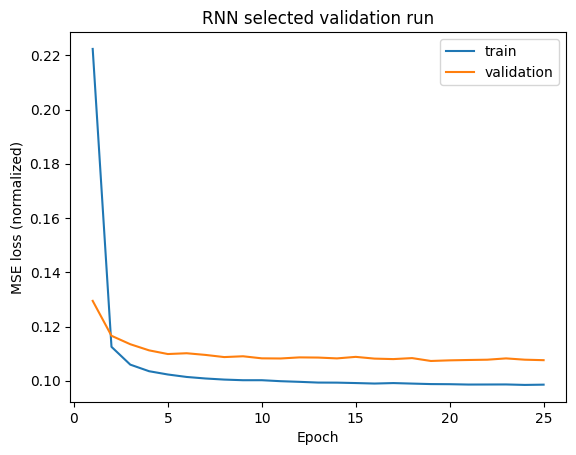

Selected RNN configuration: {'model': 'RNN', 'k': 7, 'hidden_size': 32, 'layers': 2, 'lr': 0.0003, 'weight_decay': 0.0, 'epochs': 19, 'mean_val_mse': 0.10729600615813048}
RNN tuning results:


,model,k,hidden_size,layers,lr,weight_decay,seed,best_epoch,val_mse,parameters
4,RNN,7,32,2,0.0003,0.0000,42,19,0.107296,3460
3,RNN,7,16,2,0.0003,0.0000,42,33,0.107808,964
2,RNN,7,32,2,0.0010,0.0000,42,12,0.108051,3460
1,RNN,7,16,2,0.0010,0.0000,42,20,0.108329,964
5,RNN,7,16,2,0.0010,0.0001,42,20,0.108475,964
0,RNN,7,8,2,0.0010,0.0000,42,33,0.108966,292


... Final training on combined 2009-2015 data
Final training average MSE (last epoch): 0.10003
Finished training RNN for 19 epochs


In [37]:
# RNN model study
rnn_config, rnn_k_results, rnn_tuning_results, rnn_confirmation = run_model_study("RNN")

print("RNN tuning results:")
display(rnn_tuning_results)

# Final training on combined 2009-2015 data
print("... Final training on combined 2009-2015 data")
rnn_model = run_full_training(rnn_config)

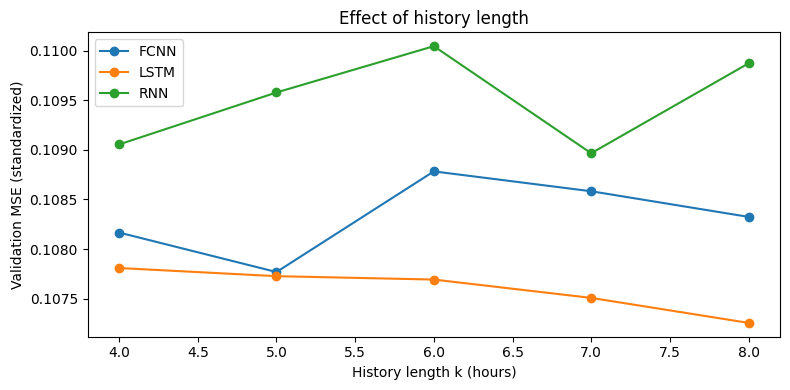

In [38]:
# Comparison plot for the k study, using validation MSE (no test data) with hidden=8, lr=0.001, wd=0, seed=42
k_results = pd.concat([fc_k_results, lstm_k_results, rnn_k_results], ignore_index=True)
plt.figure(figsize=(8, 4))
for name, group in k_results.groupby('model'):
    plt.plot(group['k'], group['val_mse'], marker='o', label=name)
plt.xlabel('History length k (hours)')
plt.ylabel('Validation MSE (standardized)')
plt.title('Effect of history length')
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / 'k_study.png', dpi=160)
plt.show()
k_results.to_csv(RESULT_DIR / 'k_study_all.csv', index=False)

# Evaluation

,model,attribute,MAE,RMSE
0,FCNN,p (mbar),0.248929,0.328604
1,FCNN,T (degC),0.560951,0.769135
2,FCNN,rh (%),2.601281,3.732134
3,FCNN,wv (m/s),0.613610,0.850659
4,LSTM,p (mbar),0.266127,0.356555
5,LSTM,T (degC),0.540482,0.763158
6,LSTM,rh (%),2.454110,3.624810
7,LSTM,wv (m/s),0.621415,0.855077
8,RNN,p (mbar),0.257552,0.347083
9,RNN,T (degC),0.536717,0.767097


,model,k,standardized_MSE,standardized_RMSE
0,FCNN,7,0.092344,0.303881
1,LSTM,7,0.092455,0.304064
2,RNN,7,0.093091,0.305108


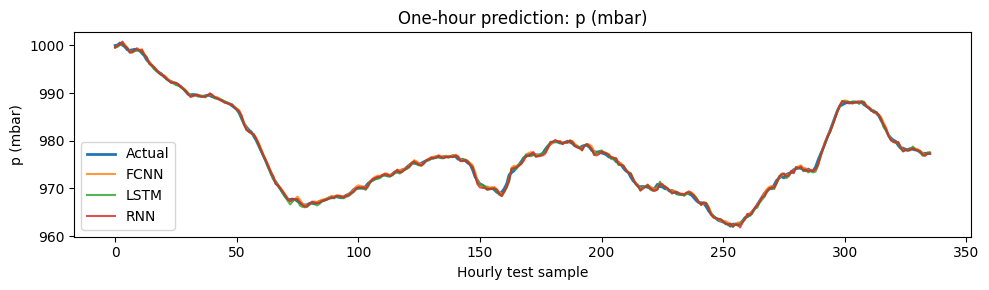

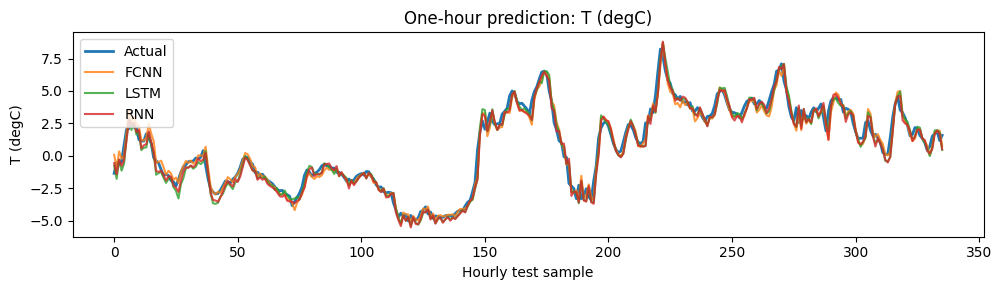

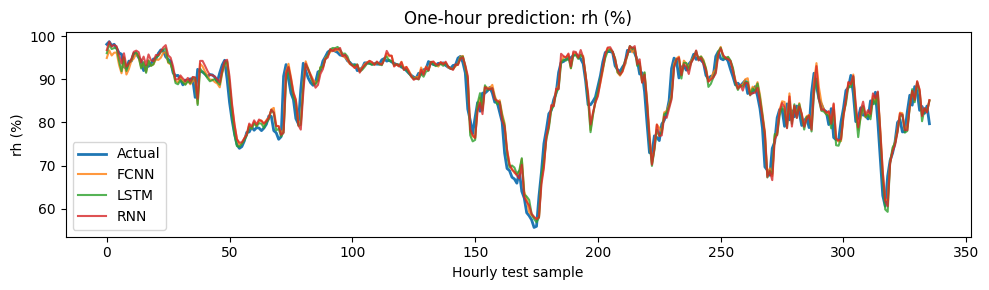

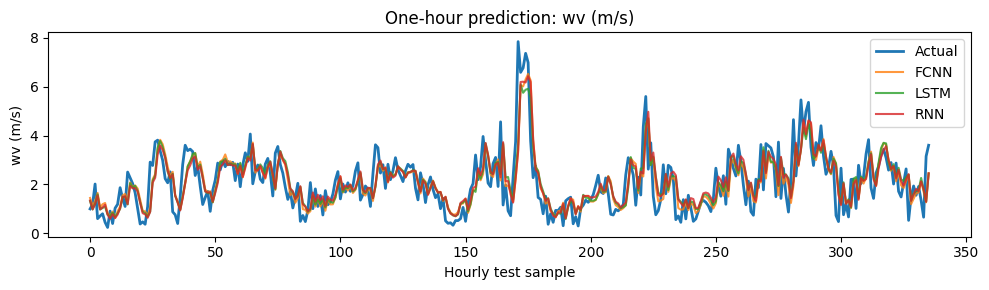

In [39]:
# Final test-set evaluation (run only AFTER all hyperparameters are selected).
from sklearn.metrics import mean_absolute_error, mean_squared_error

final_models = {'FCNN': (fc_model, fc_config),
                'LSTM': (lstm_model, lstm_config),
                'RNN': (rnn_model, rnn_config)}

def get_predictions(model, loader):
    """Collect normalized model predictions and labels, preserving order."""
    model.eval()
    predictions, targets = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(DEVICE)).cpu().numpy()
            predictions.append(out)
            targets.append(y.numpy())
    return np.concatenate(predictions), np.concatenate(targets)

def evaluate_one_step(model, selected_k):
    """Test metrics in original weather units and standardized overall MSE."""
    loader = get_k_data(selected_k)['test_loader']
    pred_std, target_std = get_predictions(model, loader)
    pred = scaler.inverse_transform(pred_std)
    target = scaler.inverse_transform(target_std)
    errors = pred - target
    by_attribute = []
    for j, feature in enumerate(target_cols):
        by_attribute.append({
            'attribute': feature,
            'MAE': float(np.mean(np.abs(errors[:, j]))),
            'RMSE': float(np.sqrt(np.mean(errors[:, j] ** 2))),
        })
    overall = float(np.mean((pred_std - target_std) ** 2))
    return by_attribute, overall, pred, target


# Evaluate all three models on the test set
all_metrics = []
overall_metrics = []
saved_predictions = {}

for model_name, (model, cfg) in final_models.items():
    per_attr, overall, pred, truth = evaluate_one_step(model, cfg['k'])

    saved_predictions[model_name] = pred
    all_metrics.extend({'model': model_name, **row} for row in per_attr)

    overall_metrics.append({
        'model': model_name,
        'k': cfg['k'],
        'standardized_MSE': overall,
        'standardized_RMSE': np.sqrt(overall)
    })

# Display evaluation results
attribute_metrics = pd.DataFrame(all_metrics)
overall_metrics = pd.DataFrame(overall_metrics).sort_values('standardized_MSE')

display(attribute_metrics)
display(overall_metrics)

# Plot actual vs predicted values (2 weeks)
truth = scaler.inverse_transform(aligned_windows['test'][1])
days = min(24 * 14, len(truth))

for j, feature in enumerate(target_cols):
    plt.figure(figsize=(10, 3))

    plt.plot(truth[:days, j], label='Actual', linewidth=2)

    for name, pred in saved_predictions.items():
        plt.plot(pred[:days, j], label=name, alpha=0.8)

    plt.title(f'One-hour prediction: {feature}')
    plt.xlabel('Hourly test sample')
    plt.ylabel(feature)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Error propagation

In [40]:

def single_point_error_prop(model, x, y, err_func=F.mse_loss):
    """
    params:
        model: the model with a forward method to run
        x: initial historical window (k, 4)
        y: actual future values (horizon, 4)
    out:
        errs: the loss at each time step given by err_func (horizon, 4).
    """
    device = next(model.parameters()).device

    # prepare input data in tensor
    input_data = torch.as_tensor(
        x, dtype=torch.float32, device=device
    ).unsqueeze(0)

    # prepare target in tensor
    targets = torch.as_tensor(
        y, dtype=torch.float32, device=device
    )

    errs = []
    model.eval()

    with torch.no_grad():
        for yt in targets:
            y_hat = model(input_data)  # (1, 4)

            # Squared error for each weather attribute
            err = err_func(y_hat.squeeze(0), yt, reduction="none")
            errs.append(err.cpu().numpy())

            # Remove oldest observation, append prediction
            input_data = torch.cat(
                [input_data[:, 1:, :], y_hat.unsqueeze(1)],
                dim=1
            )

    return np.stack(errs)



def display_avg_error_prop(model, x_set, y_set, err_func, name):
    errs = np.stack([single_point_error_prop(model, x, y, err_func)for x, y in zip(x_set, y_set)])

    # Shape: (starting_points, 24, 4)

    # Average over starting points only
    mean_mse = errs.mean(axis=0)  # (24, 4)

    # Average across attributes for overall error
    overall_mse = mean_mse.mean(axis=1)  # (24,)

    plt.plot(
        range(1, len(overall_mse) + 1),
        overall_mse,
        label=name
    )

    return mean_mse

In [44]:
# Prepare test data for error propagation
HORIZON = 24  # Predict 24 hours ahead
STRIDE = 1   # Start a new forecast every 1 hours

# Existing aligned test windows (built using MAX_K=8)
x8_test, y8_test = aligned_windows["test"]

# Find the segment associated with each prediction target
metadata = pd.concat([
    seg[["Date Time", "segment"]].iloc[MAX_K:]
    for _, seg in test_norm.groupby("segment")
    if len(seg) > MAX_K
], ignore_index=True)

assert len(metadata) == len(y8_test)

# Select starting points that allow 24 consecutive predictions
origins = []

for _, group in metadata.groupby("segment"):
    indices = group.index.to_numpy()

    for i in range(0, len(indices) - HORIZON + 1, STRIDE):
        origins.append(indices[i])

origins = np.array(origins, dtype=int)

# Actual future measurements for each starting point
y_set = np.stack([
    y8_test[i:i + HORIZON]
    for i in origins
])

print("Forecast starting points:", len(origins))
print("Actual future values:", y_set.shape)

Forecast starting points: 8648
Actual future values: (8648, 24, 4)


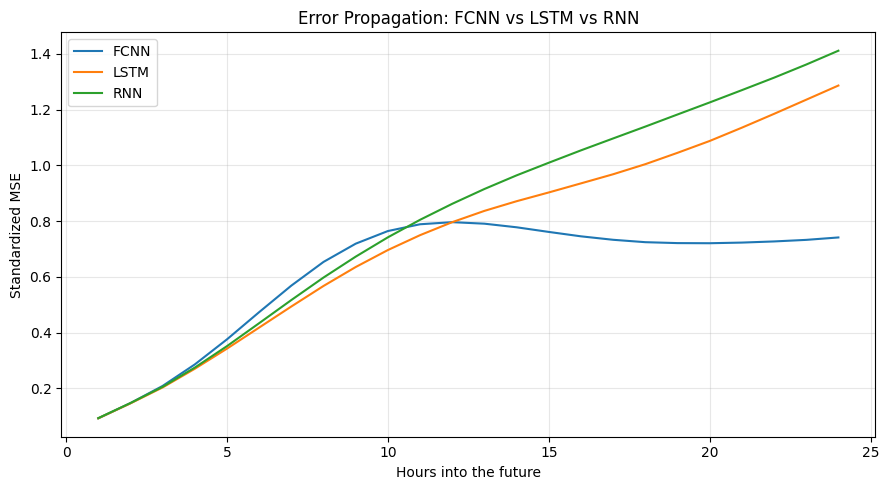

In [45]:
# Run error propagation for all three models
propagation_results = {}

plt.figure(figsize=(9, 5))

for name, (model, cfg) in final_models.items():

    # Use each model's selected history length
    x_set = x8_test[origins, -cfg["k"]:, :]

    mean_mse = display_avg_error_prop(
        model,
        x_set,
        y_set,
        F.mse_loss,
        name
    )

    propagation_results[name] = mean_mse

plt.xlabel("Hours into the future")
plt.ylabel("Standardized MSE")
plt.title("Error Propagation: FCNN vs LSTM vs RNN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

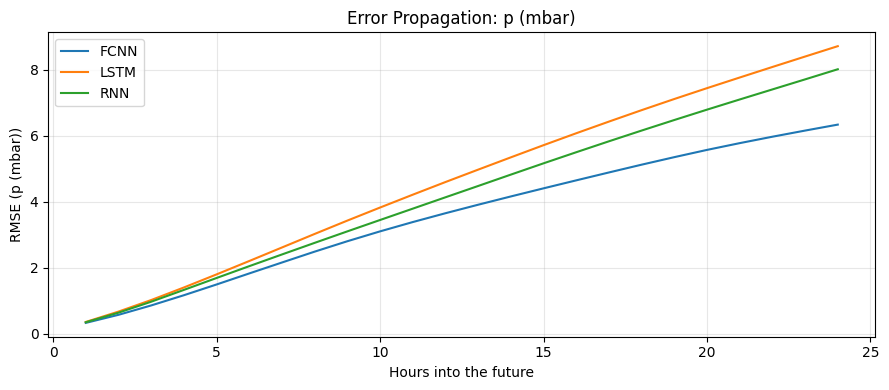

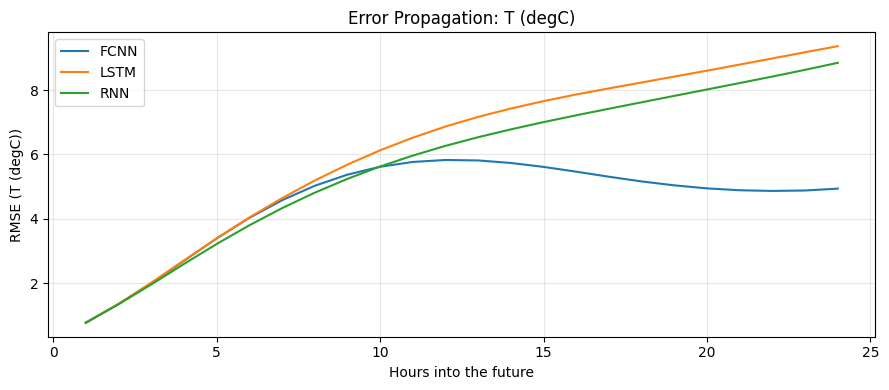

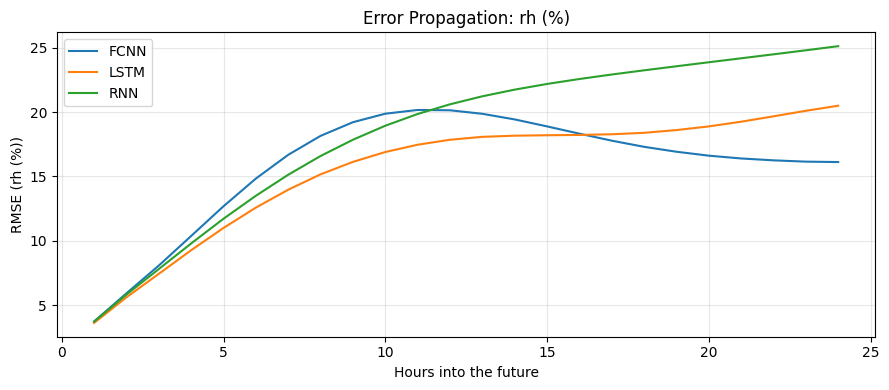

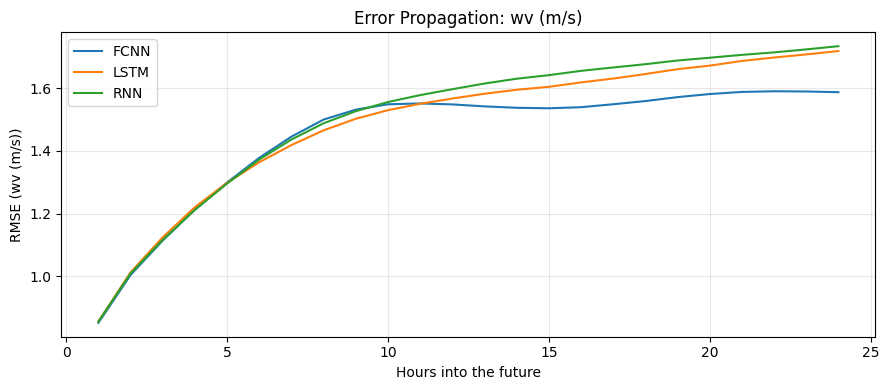

In [46]:
# Error propagation for each attribute
for j, feature in enumerate(target_cols):
    plt.figure(figsize=(9, 4))

    for name, mean_mse in propagation_results.items():

        # Convert standardized RMSE to original units
        rmse = np.sqrt(mean_mse[:, j]) * scaler.scale_[j]

        plt.plot(
            range(1, HORIZON + 1),
            rmse,
            label=name
        )

    plt.xlabel("Hours into the future")
    plt.ylabel(f"RMSE ({feature})")
    plt.title(f"Error Propagation: {feature}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [47]:

summary_rows = []

for name, mean_mse in propagation_results.items():
    for h in [1, 6, 12, 24]:
        for j, feature in enumerate(target_cols):
            summary_rows.append({
                "Model": name,
                "Hour": h,
                "Attribute": feature,
                "RMSE": np.sqrt(mean_mse[h - 1, j]) * scaler.scale_[j]
            })

propagation_summary = pd.DataFrame(summary_rows)
display(propagation_summary.round(4))


,Model,Hour,Attribute,RMSE
0,FCNN,1,p (mbar),0.3281
1,FCNN,1,T (degC),0.7686
2,FCNN,1,rh (%),3.7287
3,FCNN,1,wv (m/s),0.8520
4,FCNN,6,p (mbar),1.8252
5,FCNN,6,T (degC),4.0251
6,FCNN,6,rh (%),14.8284
7,FCNN,6,wv (m/s),1.3780
8,FCNN,12,p (mbar),3.6485
9,FCNN,12,T (degC),5.8270
